# EA3 · Comparación climática: Medellín (Colombia) vs. Madrid (España), 2019

**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Madrid durante el mismo periodo?

## Fuentes de datos

Ambas tablas provienen de la misma fuente oficial: **NOAA NCEI – Global Surface Summary of the Day (GSOD)**, que resume las observaciones diarias de estaciones meteorológicas de superficie.

- Descripción del conjunto: <https://www.ncei.noaa.gov/access/metadata/landing-page/bin/iso?id=gov.noaa.ncdc:C00516>
- Documentación de columnas, unidades y códigos: <https://www.ncei.noaa.gov/data/global-summary-of-the-day/doc/readme.txt>

| | Medellín | Madrid |
|---|---|---|
| Archivo | `datos/medellin.csv` | `datos/madrid.csv` |
| Estación | Olaya Herrera, CO (80110099999) | Barajas, SP (08221099999) |
| Enlace de descarga | [CSV Medellín](https://www.ncei.noaa.gov/access/services/data/v1?dataset=global-summary-of-the-day&stations=80110099999&startDate=2019-01-01&endDate=2019-12-31&format=csv&includeStationName=true&dataTypes=TEMP,MAX,MIN,PRCP,PRCP_ATTRIBUTES) | [CSV Madrid](https://www.ncei.noaa.gov/access/services/data/v1?dataset=global-summary-of-the-day&stations=08221099999&startDate=2019-01-01&endDate=2019-12-31&format=csv&includeStationName=true&dataTypes=TEMP,MAX,MIN,PRCP,PRCP_ATTRIBUTES) |
| Periodo | 2019-01-01 a 2019-12-31 | 2019-01-01 a 2019-12-31 |
| Frecuencia | Diaria | Diaria |

**Columnas utilizadas (iguales en ambas tablas):**

| Columna | Significado | Unidad original | Unidad usada | Código de faltante |
|---|---|---|---|---|
| `DATE` | Fecha | — | fecha | — |
| `MAX` | Temperatura máxima diaria | °F | °C | 9999.9 |
| `MIN` | Temperatura mínima diaria | °F | °C | 9999.9 |
| `PRCP` | Precipitación diaria | pulgadas | mm | 99.99 |
| `PRCP_ATTRIBUTES` | Indicador de calidad de `PRCP` | — | — | — |

Las unidades originales son las mismas en las dos tablas, pero se convierten al sistema métrico: **°C = (°F − 32) × 5/9** y **mm = pulgadas × 25.4**.

## A. Planteamiento de la comparación

- **Periodo común:** año calendario 2019 completo, con datos diarios en ambas ciudades.
- **Variables:** temperatura máxima diaria (°C), temperatura mínima diaria (°C) y precipitación diaria (mm).
- **Predicción (antes de calcular):** espero que Medellín, por estar cerca del ecuador, tenga temperaturas casi constantes todo el año y más lluvia; y que Madrid, en latitud media, muestre estaciones marcadas (invierno frío, verano caluroso) y menos lluvia.

## B. Carga y revisión de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

med = pd.read_csv("datos/medellin.csv")
mad = pd.read_csv("datos/madrid.csv")

for nombre, df in [("Medellín", med), ("Madrid", mad)]:
    print(nombre)
    print("  columnas:", list(df.columns))
    print("  dimensiones:", df.shape)
    print("  fecha inicial:", df["DATE"].min(), "| fecha final:", df["DATE"].max())
    print("  fechas duplicadas:", df["DATE"].duplicated().sum())

Medellín
  columnas: ['STATION', 'NAME', 'DATE', 'MAX', 'MIN', 'PRCP', 'PRCP_ATTRIBUTES', 'TEMP']
  dimensiones: (365, 8)
  fecha inicial: 2019-01-01 | fecha final: 2019-12-31
  fechas duplicadas: 0
Madrid
  columnas: ['STATION', 'NAME', 'DATE', 'MAX', 'MIN', 'PRCP', 'PRCP_ATTRIBUTES', 'TEMP']
  dimensiones: (365, 8)
  fecha inicial: 2019-01-01 | fecha final: 2019-12-31
  fechas duplicadas: 0


In [2]:
med.head(3)

,STATION,NAME,DATE,MAX,MIN,PRCP,PRCP_ATTRIBUTES,TEMP
0,80110099999,"OLAYA HERRERA, CO",2019-01-01,87.8,57.2,0.0,G,78.6
1,80110099999,"OLAYA HERRERA, CO",2019-01-02,87.8,58.6,0.0,G,78.0
2,80110099999,"OLAYA HERRERA, CO",2019-01-03,87.8,57.2,0.0,G,76.9


In [3]:
mad.head(3)

,STATION,NAME,DATE,MAX,MIN,PRCP,PRCP_ATTRIBUTES,TEMP
0,8221099999,"BARAJAS, SP",2019-01-01,59.0,25.9,0.0,G,37.9
1,8221099999,"BARAJAS, SP",2019-01-02,55.9,23.0,0.0,G,36.2
2,8221099999,"BARAJAS, SP",2019-01-03,57.2,26.6,0.0,G,38.2


### Limpieza, tipos y unidades

- Las fechas se convierten a tipo fecha y las mediciones a números decimales.
- Los códigos `9999.9` y `99.99` se convierten en `NaN` (faltante). **No se reemplazan por cero.**
- Según la documentación de GSOD, un `PRCP` de 0.00 con indicador `H` o `I` significa que la estación no reportó un total confiable (pudo haber llovido), así que esos días también se tratan como faltantes. Los demás ceros sí representan días sin lluvia reportada.
- Luego se convierten las unidades a °C y mm.

In [4]:
def limpiar(df):
    out = pd.DataFrame({"fecha": pd.to_datetime(df["DATE"])})
    out["tmax"] = (df["MAX"].replace(9999.9, np.nan) - 32) * 5 / 9       # °F -> °C
    out["tmin"] = (df["MIN"].replace(9999.9, np.nan) - 32) * 5 / 9       # °F -> °C
    prcp = df["PRCP"].replace(99.99, np.nan)
    prcp = prcp.mask(df["PRCP_ATTRIBUTES"].isin(["H", "I"]))             # ceros no confiables
    out["prcp"] = prcp * 25.4                                            # pulgadas -> mm
    return out

med_l, mad_l = limpiar(med), limpiar(mad)

print("Tipos de datos:", med_l.dtypes.astype(str).to_dict())
print("Faltantes Medellín:", med_l.isna().sum().to_dict())
print("Faltantes Madrid:  ", mad_l.isna().sum().to_dict())

Tipos de datos: {'fecha': 'datetime64[us]', 'tmax': 'float64', 'tmin': 'float64', 'prcp': 'float64'}
Faltantes Medellín: {'fecha': 0, 'tmax': 0, 'tmin': 0, 'prcp': 38}
Faltantes Madrid:   {'fecha': 0, 'tmax': 0, 'tmin': 0, 'prcp': 0}


In [5]:
# Se conservan solo las fechas con todas las mediciones válidas en AMBAS tablas
datos = med_l.merge(mad_l, on="fecha", suffixes=("_med", "_mad")).dropna()
print("Días en cada tabla:", len(med_l), "y", len(mad_l))
print("Días válidos en ambas ciudades:", len(datos))
datos.head(3)

Días en cada tabla: 365 y 365
Días válidos en ambas ciudades: 327


,fecha,tmax_med,tmin_med,prcp_med,tmax_mad,tmin_mad,prcp_mad
0,2019-01-01,31.0,14.000000,0.0,15.000000,-3.388889,0.0
1,2019-01-02,31.0,14.777778,0.0,13.277778,-5.000000,0.0
2,2019-01-03,31.0,14.000000,0.0,14.000000,-3.000000,0.0


**Resultado:** las dos tablas tienen 365 filas (un año completo), sin fechas duplicadas. La temperatura no tiene faltantes; la precipitación de Medellín tiene 38 días faltantes y la de Madrid ninguno. Para comparar día a día se usan los **327 días** con datos válidos en ambas ciudades.

## C. Análisis con NumPy

Se construyen arrays de dos columnas: la columna 0 es Medellín y la columna 1 es Madrid.

In [6]:
ciudades = ["Medellín", "Madrid"]
fechas = datos["fecha"].to_numpy()
meses = datos["fecha"].dt.month.to_numpy()
tmax = datos[["tmax_med", "tmax_mad"]].to_numpy()
tmin = datos[["tmin_med", "tmin_mad"]].to_numpy()
prcp = datos[["prcp_med", "prcp_mad"]].to_numpy()

# Cortes: primera semana del periodo
print("Fechas:", fechas[:7].astype("datetime64[D]"))
print("Tmax Medellín (°C):", tmax[:7, 0].round(1))
print("Tmax Madrid (°C):  ", tmax[:7, 1].round(1))
print("Lluvia últimos 5 días (mm) [Medellín, Madrid]:")
print(prcp[-5:].round(1))

Fechas: ['2019-01-01' '2019-01-02' '2019-01-03' '2019-01-04' '2019-01-05'
 '2019-01-06' '2019-01-07']
Tmax Medellín (°C): [31. 31. 31. 32. 30. 30. 28.]
Tmax Madrid (°C):   [15.  13.3 14.  13.5 12.9 16.  16. ]
Lluvia últimos 5 días (mm) [Medellín, Madrid]:
[[0.  0. ]
 [0.  0. ]
 [0.  0. ]
 [8.9 0. ]
 [8.9 0. ]]


### Máscaras booleanas

- **Día lluvioso:** precipitación ≥ 1 mm.
- **Día caluroso:** temperatura máxima > 28 °C.

Se aplica el mismo umbral a las dos ciudades.

In [7]:
UMBRAL_LLUVIA = 1.0   # mm
UMBRAL_TEMP = 28.0    # °C

lluvioso = prcp >= UMBRAL_LLUVIA
caluroso = tmax > UMBRAL_TEMP

resumen = pd.DataFrame({
    "Tmax promedio (°C)": tmax.mean(axis=0),
    "Tmax mínima (°C)": tmax.min(axis=0),
    "Tmax máxima (°C)": tmax.max(axis=0),
    "Tmin promedio (°C)": tmin.mean(axis=0),
    "Tmin mínima (°C)": tmin.min(axis=0),
    "Precipitación total (mm)": prcp.sum(axis=0),
    "Días lluviosos (>= 1 mm)": lluvioso.sum(axis=0),
    "Días calurosos (> 28 °C)": caluroso.sum(axis=0),
    "Días con Tmin < 0 °C": (tmin < 0).sum(axis=0),
}, index=ciudades).round(1).T
resumen

,Medellín,Madrid
Tmax promedio (°C),28.6,22.5
Tmax mínima (°C),23.0,5.1
Tmax máxima (°C),36.0,41.0
Tmin promedio (°C),17.9,8.8
Tmin mínima (°C),14.0,-6.0
Precipitación total (mm),1107.4,292.1
Días lluviosos (>= 1 mm),92.0,42.0
Días calurosos (> 28 °C),244.0,110.0
Días con Tmin < 0 °C,0.0,40.0


In [8]:
# Promedios y acumulados mensuales con una máscara por mes
tmax_mes = np.array([tmax[meses == m].mean(axis=0) for m in range(1, 13)])
prcp_mes = np.array([prcp[meses == m].sum(axis=0) for m in range(1, 13)])
dias_mes = np.array([(meses == m).sum() for m in range(1, 13)])

# Broadcasting: a cada mes (12, 2) se le resta el promedio anual de su ciudad (2,)
anomalia_mes = tmax_mes - tmax.mean(axis=0)

print("Días válidos por mes:", dias_mes)
print("Amplitud anual de Tmax mensual (°C):", (tmax_mes.max(axis=0) - tmax_mes.min(axis=0)).round(1))
pd.DataFrame(np.hstack([tmax_mes, prcp_mes, anomalia_mes]).round(1), index=range(1, 13),
             columns=["Tmax Med", "Tmax Mad", "Lluvia Med", "Lluvia Mad", "Anomalía Med", "Anomalía Mad"])

Días válidos por mes: [29 26 22 25 24 29 27 29 28 29 28 31]
Amplitud anual de Tmax mensual (°C): [ 2.8 22.9]


,Tmax Med,Tmax Mad,Lluvia Med,Lluvia Mad,Anomalía Med,Anomalía Mad
1,28.6,12.6,84.6,10.7,0.0,-9.9
2,29.1,15.9,51.6,8.1,0.5,-6.6
3,28.7,19.4,139.4,12.2,0.1,-3.1
4,28.3,18.2,169.2,42.4,-0.3,-4.3
5,28.5,26.1,108.5,0.0,-0.1,3.6
6,28.9,31.1,59.9,2.5,0.3,8.6
7,28.9,35.5,30.5,16.8,0.3,13.0
8,30.0,33.3,6.1,44.2,1.4,10.8
9,29.1,28.0,114.6,38.1,0.5,5.5
10,27.2,23.0,130.3,32.0,-1.4,0.5


## D. Gráficas comparativas

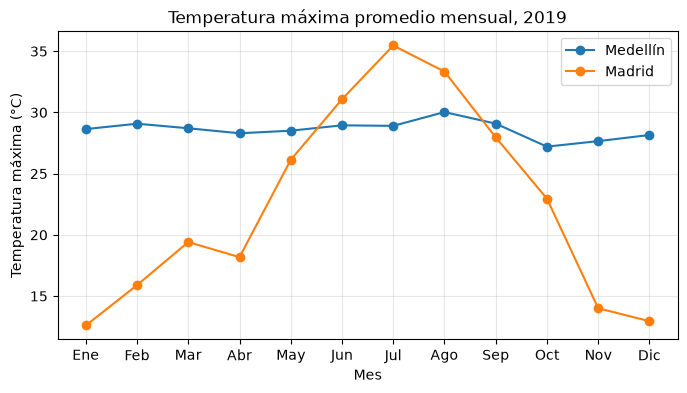

In [9]:
nombres_mes = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
x = np.arange(12)

plt.figure(figsize=(8, 4))
plt.plot(x, tmax_mes[:, 0], marker="o", label="Medellín")
plt.plot(x, tmax_mes[:, 1], marker="o", label="Madrid")
plt.xticks(x, nombres_mes)
plt.title("Temperatura máxima promedio mensual, 2019")
plt.xlabel("Mes")
plt.ylabel("Temperatura máxima (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Patrón:** la línea de Medellín es casi plana: va de 27.2 °C (octubre) a 30.0 °C (agosto), una amplitud de 2.8 °C. La de Madrid sube de 12.6 °C (enero) a 35.5 °C (julio), una amplitud de 22.9 °C. Entre junio y agosto Madrid supera a Medellín; en junio y septiembre las dos ciudades quedan a unos 1–2 °C de distancia.

**Lo que no permite concluir:** es un solo año, así que no describe el clima típico de cada ciudad; el promedio mensual oculta la variación diaria; y la gráfica no explica por qué ocurre la diferencia.

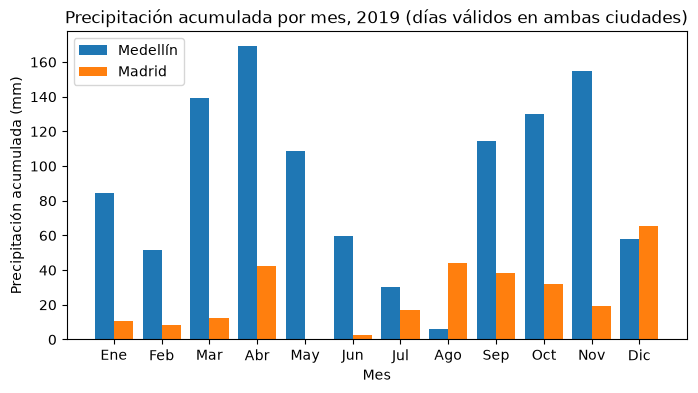

In [10]:
ancho = 0.4
plt.figure(figsize=(8, 4))
plt.bar(x - ancho / 2, prcp_mes[:, 0], ancho, label="Medellín")
plt.bar(x + ancho / 2, prcp_mes[:, 1], ancho, label="Madrid")
plt.xticks(x, nombres_mes)
plt.title("Precipitación acumulada por mes, 2019 (días válidos en ambas ciudades)")
plt.xlabel("Mes")
plt.ylabel("Precipitación acumulada (mm)")
plt.legend()
plt.show()

**Patrón:** Medellín acumula más lluvia que Madrid en 10 de los 12 meses; las excepciones son agosto (6.1 mm frente a 44.2 mm) y diciembre (57.9 mm frente a 65.5 mm). Medellín muestra dos picos (abril, 169.2 mm; noviembre, 154.9 mm) y Madrid tiene sus máximos en diciembre (65.5 mm) y agosto (44.2 mm). En ambas ciudades junio y julio quedaron por debajo de su promedio mensual de lluvia (92.3 mm en Medellín y 24.3 mm en Madrid).

**Lo que no permite concluir:** los acumulados solo suman los días válidos, y cada mes perdió entre 0 y 9 días (marzo solo tiene 22), así que no son los totales mensuales reales y están subestimados en ambas ciudades. Tampoco se puede afirmar que este reparto de lluvias se repita en otros años.

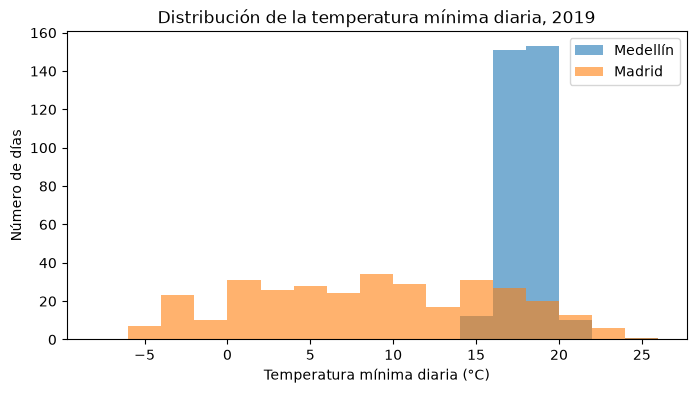

In [11]:
bins = np.arange(-8, 28, 2)
plt.figure(figsize=(8, 4))
plt.hist(tmin[:, 0], bins=bins, alpha=0.6, label="Medellín")
plt.hist(tmin[:, 1], bins=bins, alpha=0.6, label="Madrid")
plt.title("Distribución de la temperatura mínima diaria, 2019")
plt.xlabel("Temperatura mínima diaria (°C)")
plt.ylabel("Número de días")
plt.legend()
plt.show()

**Patrón:** las mínimas de Medellín se concentran en un rango estrecho (de 14.0 °C a unos 21 °C, promedio 17.9 °C), mientras que las de Madrid se reparten desde −6.0 °C hasta 24.4 °C (promedio 8.8 °C), con 40 días por debajo de 0 °C. Medellín no tuvo ningún día bajo cero.

**Lo que no permite concluir:** el histograma no muestra en qué fechas ocurrió cada valor. Además, Medellín tiene una mínima aislada de 25.0 °C, muy lejos del resto, que podría ser un error de registro; con estos datos no se puede confirmar.

## E. Interpretación de resultados

**Respuesta a la pregunta guía** (2019, 327 días válidos en ambas ciudades):

1. **Diferencia – estacionalidad de la temperatura.** La temperatura máxima mensual de Medellín varió solo 2.8 °C en el año (27.2 °C a 30.0 °C), mientras que la de Madrid varió 22.9 °C (12.6 °C a 35.5 °C). La máxima diaria fue en promedio 28.6 °C en Medellín y 22.5 °C en Madrid.
2. **Diferencia – precipitación.** Medellín acumuló 1107.4 mm en 92 días lluviosos; Madrid, 292.1 mm en 42 días lluviosos. Es decir, cerca de 3.8 veces más lluvia y algo más del doble de días lluviosos.
3. **Similitud – calor a mitad de año y días secos.** En junio y septiembre las máximas mensuales fueron parecidas (28.9 °C y 29.1 °C en Medellín; 31.1 °C y 28.0 °C en Madrid), y ambas ciudades tuvieron muchos días por encima de 28 °C (244 en Medellín y 110 en Madrid). Además, en las dos ciudades la mayoría de los días no fueron lluviosos (235 de 327 en Medellín y 285 de 327 en Madrid), y junio y julio tuvieron menos lluvia que su promedio mensual.

**Sobre la predicción:** se cumplió en lo esencial (Medellín más estable y lluviosa; Madrid con estaciones marcadas y más seca). No esperaba que Madrid superara a Medellín en temperatura máxima durante el verano.

**Efecto del periodo común y de los datos faltantes:**

- Usar el mismo año, la misma frecuencia y la misma fuente hace que las diferencias no se deban a periodos o métodos distintos. Sin embargo, un solo año no representa el clima de largo plazo.
- Se descartaron 38 días (10 % del año) porque Medellín no tenía un dato confiable de lluvia. Por eso la precipitación total y el número de días lluviosos están subestimados frente al año completo, y los meses con más días descartados (marzo, mayo, abril) son los más afectados. Los faltantes no se reemplazaron por cero.
- Cada ciudad está representada por una sola estación ubicada en un aeropuerto, que no necesariamente refleja toda la ciudad.

**Causalidad:** estos resultados describen diferencias y coincidencias observadas en 2019. No demuestran qué las causa (latitud, altitud, relieve u otros factores); para eso se necesitarían más datos y otro tipo de análisis.

### Verificación final

- Las tablas son de Medellín (Colombia) y Madrid (España).
- Ambas cubren del 2019-01-01 al 2019-12-31 con frecuencia diaria.
- El notebook incluye las fuentes, las variables y las unidades.
- El análisis usa NumPy (cortes, máscaras, broadcasting) y tres gráficas comparativas.